In [1]:
import pandas as pd

hotels = pd.read_csv('/kaggle/input/hotels/hotels.csv')
reviews = pd.read_csv('/kaggle/input/hotels/reviews.csv')
users = pd.read_csv('/kaggle/input/hotels/users.csv')

In [2]:
#rename 
hotels_rename = {
    'hotel_id': 'hotel_id',          
    'hotel_name': 'hotel_name',
    'city': 'hotel_city',
    'country': 'hotel_country',     
    'star_rating': 'hotel_star_rating',
    'lat': 'hotel_lat',
    'lon': 'hotel_lon',
    'cleanliness_base': 'hotel_cleanliness_base',
    'comfort_base': 'hotel_comfort_base',
    'facilities_base': 'hotel_facilities_base',
    'location_base': 'hotel_location_base',
    'staff_base': 'hotel_staff_base',
    'value_for_money_base': 'hotel_value_for_money_base'
}

reviews_rename = {
    'review_id': 'review_id',
    'user_id': 'user_id',            
    'hotel_id': 'hotel_id',            
    'review_date': 'review_date',
    'score_overall': 'score_overall',
    'score_cleanliness': 'score_cleanliness',
    'score_comfort': 'score_comfort',
    'score_facilities': 'score_facilities',
    'score_location': 'score_location',
    'score_staff': 'score_staff',
    'score_value_for_money': 'score_value_for_money',
    'review_text': 'review_text'
}

users_rename = {
    'user_id': 'user_id',          
    'user_gender': 'user_gender',
    'country': 'user_country',       
    'age_group': 'user_age_group',
    'traveller_type': 'user_traveller_type',
    'join_date': 'user_join_date'
}

#Apply renames
hotels = hotels.rename(columns=hotels_rename)
reviews = reviews.rename(columns=reviews_rename)
users = users.rename(columns=users_rename)

# quick view of columns after rename
print("hotels cols:", hotels.columns.tolist())
print("reviews cols:", reviews.columns.tolist())
print("users cols:", users.columns.tolist())

hotels cols: ['hotel_id', 'hotel_name', 'hotel_city', 'hotel_country', 'hotel_star_rating', 'hotel_lat', 'hotel_lon', 'hotel_cleanliness_base', 'hotel_comfort_base', 'hotel_facilities_base', 'hotel_location_base', 'hotel_staff_base', 'hotel_value_for_money_base']
reviews cols: ['review_id', 'user_id', 'hotel_id', 'review_date', 'score_overall', 'score_cleanliness', 'score_comfort', 'score_facilities', 'score_location', 'score_staff', 'score_value_for_money', 'review_text']
users cols: ['user_id', 'user_gender', 'user_country', 'user_age_group', 'user_traveller_type', 'user_join_date']


In [3]:
# Merge reviews with users on user_id
reviews_users = pd.merge(
    reviews,
    users,
    on='user_id',
    how='left',  # keep all reviews even if user info missing
    validate='many_to_one'  # many reviews to one user
)


# Merge the result with hotels on hotel_id
merged_df = pd.merge(
    reviews_users,
    hotels,
    on='hotel_id',
    how='left',  # keep all reviews even if hotel info missing
    validate='many_to_one'  # many reviews to one hotel
)

In [4]:
columns_to_drop = [
    'review_text',
    'review_date',
    'user_join_date',
    'hotel_lat',
    'hotel_lon'
]

# Drop the columns
merged_df = merged_df.drop(columns=columns_to_drop)
print(f"Dropped: {columns_to_drop}")
print(f"Dataset shape after dropping columns: {merged_df.shape}")
print(f"Final columns list:\n{merged_df.columns.tolist()}")

Dropped: ['review_text', 'review_date', 'user_join_date', 'hotel_lat', 'hotel_lon']
Dataset shape after dropping columns: (50000, 24)
Final columns list:
['review_id', 'user_id', 'hotel_id', 'score_overall', 'score_cleanliness', 'score_comfort', 'score_facilities', 'score_location', 'score_staff', 'score_value_for_money', 'user_gender', 'user_country', 'user_age_group', 'user_traveller_type', 'hotel_name', 'hotel_city', 'hotel_country', 'hotel_star_rating', 'hotel_cleanliness_base', 'hotel_comfort_base', 'hotel_facilities_base', 'hotel_location_base', 'hotel_staff_base', 'hotel_value_for_money_base']


In [5]:
merged_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 24 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   review_id                   50000 non-null  int64  
 1   user_id                     50000 non-null  int64  
 2   hotel_id                    50000 non-null  int64  
 3   score_overall               50000 non-null  float64
 4   score_cleanliness           50000 non-null  float64
 5   score_comfort               50000 non-null  float64
 6   score_facilities            50000 non-null  float64
 7   score_location              50000 non-null  float64
 8   score_staff                 50000 non-null  float64
 9   score_value_for_money       50000 non-null  float64
 10  user_gender                 50000 non-null  object 
 11  user_country                50000 non-null  object 
 12  user_age_group              50000 non-null  object 
 13  user_traveller_type         500

# Question 1: Which city is best for each traveler type?

In [6]:
print("different travel types:" , merged_df['user_traveller_type'].unique())
print("-------------------------")
print("different cities:" ,merged_df['hotel_city'].unique())

different travel types: ['Solo' 'Couple' 'Business' 'Family']
-------------------------
different cities: ['New York' 'Tokyo' 'Cairo' 'Barcelona' 'Moscow' 'Sydney' 'Buenos Aires'
 'Singapore' 'Mumbai' 'Cape Town' 'Berlin' 'Wellington' 'Paris' 'Shanghai'
 'Lagos' 'London' 'Bangkok' 'Istanbul' 'Mexico City' 'Toronto' 'Dubai'
 'Seoul' 'Amsterdam' 'Rome' 'Rio de Janeiro']


In [7]:
#group reviews by traveler type and city
#calculate the average score overall score for each group
#remove the grouping index back to normal index
city_scores = merged_df.groupby(['user_traveller_type', 'hotel_city'])['score_overall'].mean().reset_index()
city_scores.head()

,user_traveller_type,hotel_city,score_overall
0,Business,Amsterdam,8.964348
1,Business,Bangkok,8.886265
2,Business,Barcelona,8.904545
3,Business,Berlin,8.868122
4,Business,Buenos Aires,8.690000


In [8]:
#find the row with the highest score for each traveler type.
best_city_per_type = city_scores.loc[city_scores.groupby('user_traveller_type')['score_overall'].idxmax()]

In [9]:
best_city_per_type

,user_traveller_type,hotel_city,score_overall
7,Business,Dubai,8.965668
25,Couple,Amsterdam,9.096989
57,Family,Dubai,9.214381
75,Solo,Amsterdam,9.108454


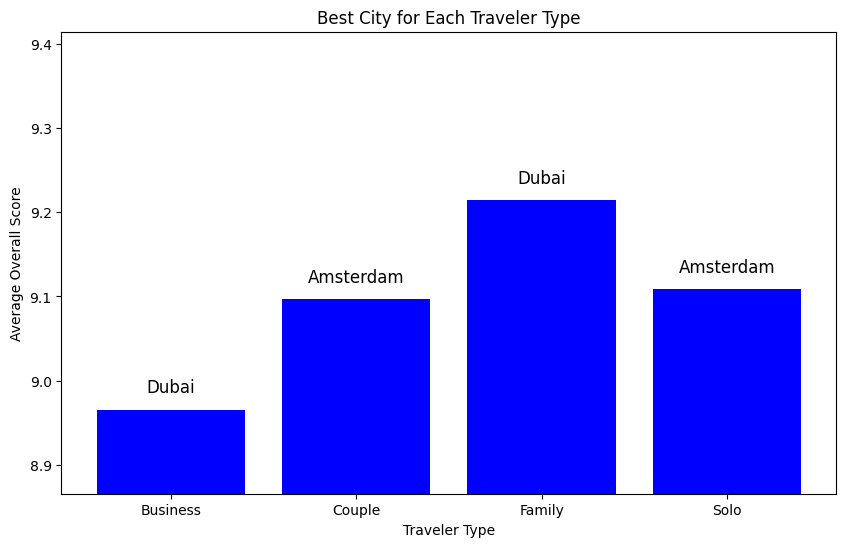

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))
plt.bar(best_city_per_type['user_traveller_type'], 
        best_city_per_type['score_overall'], 
        color='blue')


for i, (traveler, city, score) in enumerate(zip(best_city_per_type['user_traveller_type'], 
                                                best_city_per_type['hotel_city'], 
                                                best_city_per_type['score_overall'])):
    plt.text(i, score + 0.02, city, ha='center', fontsize=12)

plt.xlabel("Traveler Type")
plt.ylabel("Average Overall Score")
plt.title("Best City for Each Traveler Type")
plt.ylim(best_city_per_type['score_overall'].min() - 0.1, 
         best_city_per_type['score_overall'].max() + 0.2)
plt.show()

Dubai performs best for both Family travelers (with the highest score overall at $9.21$) and Business travelers.

Amsterdam is the preferred city for Couple and Solo travelers, both earning very high average scores over $9.0$.

# Question 2: Top 3 Countries with Best Value-for-Money per Age Group

In [11]:
print(merged_df['user_age_group'].unique())

['25-34' '35-44' '55+' '45-54' '18-24']


In [15]:
#group age group with country
#get the average score value for money
#reset index
avg_value = merged_df.groupby(['user_age_group', 'hotel_country'])['score_value_for_money'].mean().reset_index()

In [16]:
#sort age group ascending but score value for money in descending
#get top 3
avg_value = avg_value.sort_values(['user_age_group', 'score_value_for_money'], ascending=[True, False])
top3 = avg_value.groupby('user_age_group').head(3) 
top3

,user_age_group,hotel_country,score_value_for_money
4,18-24,China,8.706926
12,18-24,Netherlands,8.704911
3,18-24,Canada,8.661261
29,25-34,China,8.727941
37,25-34,Netherlands,8.683442
44,25-34,Spain,8.625074
54,35-44,China,8.700799
62,35-44,Netherlands,8.693268
63,35-44,New Zealand,8.646429
79,45-54,China,8.722112


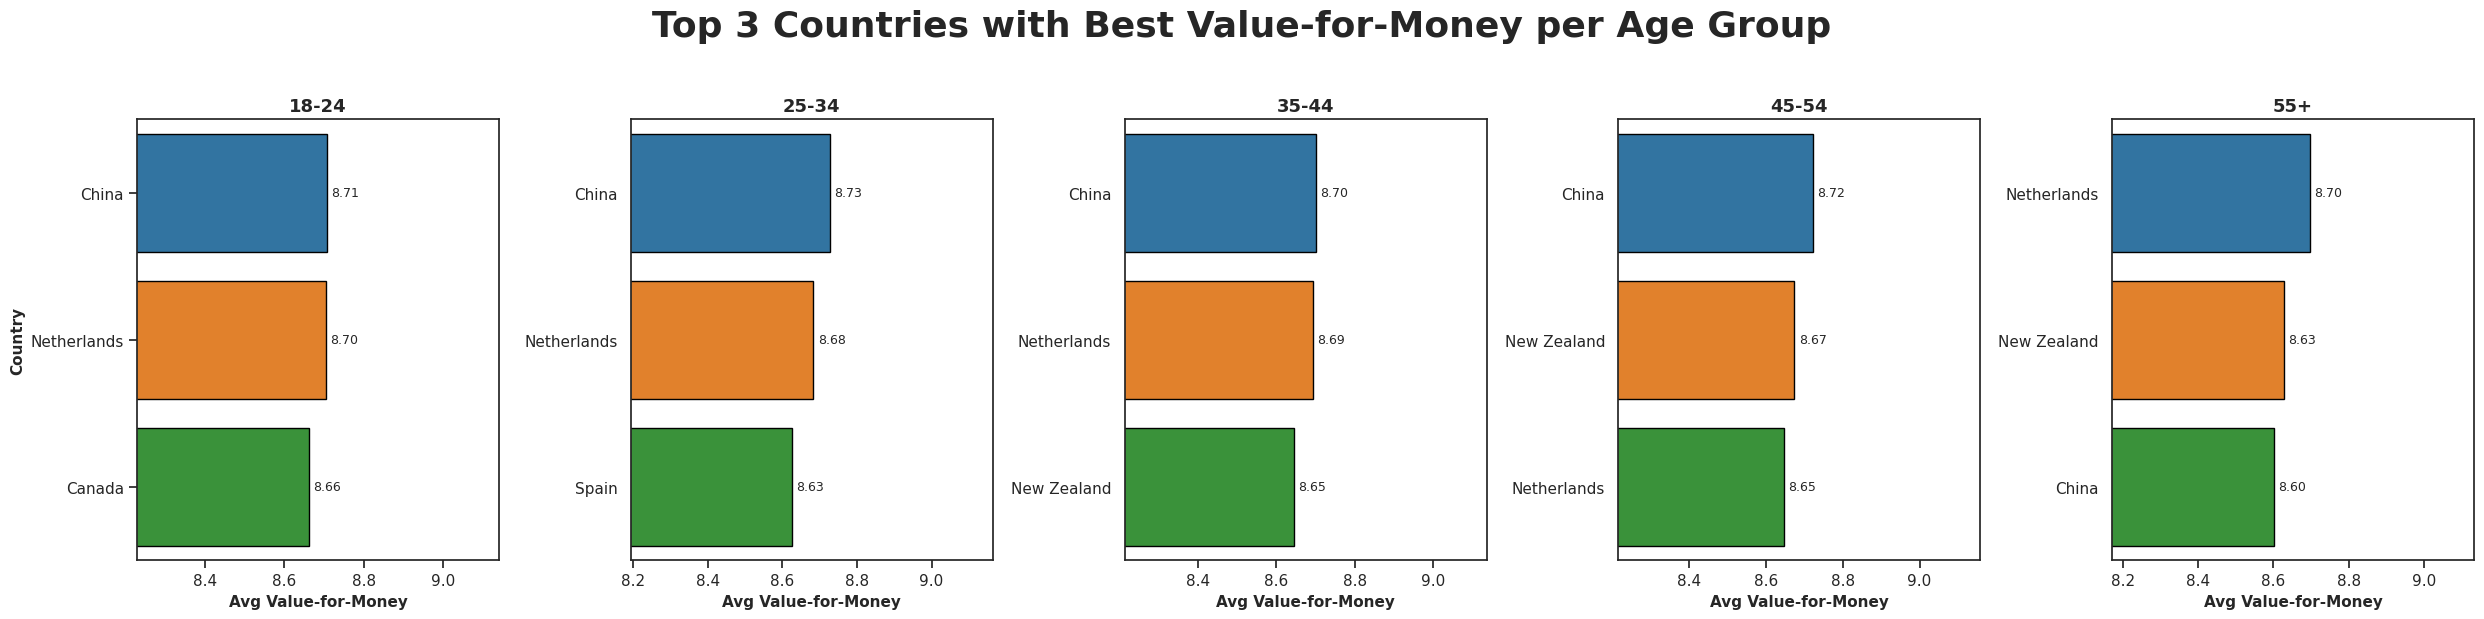

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns


sns.set(style="ticks") 


age_groups = top3['user_age_group'].unique()

# create one plot for each age group
plt.figure(figsize=(5 * len(age_groups), 6))

for i, group in enumerate(age_groups, start=1):
    # filter only this age group
    group_data = top3[top3['user_age_group'] == group].sort_values(
        by='score_value_for_money', ascending=False
    )

    # a subplot
    plt.subplot(1, len(age_groups), i)


    sns.barplot(
        data=group_data,
        y='hotel_country',
        x='score_value_for_money',
        palette='tab10',  # bright colors
        edgecolor='black'
    )


    plt.title(f'{group}', fontsize=13, fontweight='bold')
    plt.xlabel('Avg Value-for-Money', fontsize=11, fontweight='bold')

    # only show y label on first plot
    if i == 1:
        plt.ylabel('Country', fontsize=11 , fontweight='bold')
    else:
        plt.ylabel('')
        plt.tick_params(axis='y', left=False)

    # add numbers on bars
    for container in plt.gca().containers:
        plt.bar_label(container, fmt='%.2f', fontsize=9, padding=3)

    # zoom in on the range to exaggerate differences
    min_score = group_data['score_value_for_money'].min()
    max_score = group_data['score_value_for_money'].max()
    plt.xlim(min_score * 0.95, max_score * 1.05)

plt.suptitle('Top 3 Countries with Best Value-for-Money per Age Group', 
             fontsize=26, fontweight='bold', y=1.03)

plt.tight_layout()
plt.show()

# Add new country_group column

In [18]:
#new country group column
country_groups_map = {
    'United States': 'North_America', 'Canada': 'North_America',
    'Germany': 'Western_Europe', 'France': 'Western_Europe', 'United Kingdom': 'Western_Europe',
    'Netherlands': 'Western_Europe', 'Spain': 'Western_Europe', 'Italy': 'Western_Europe',
    'Russia': 'Eastern_Europe',
    'China': 'East_Asia', 'Japan': 'East_Asia', 'South Korea': 'East_Asia',
    'Thailand': 'Southeast_Asia', 'Singapore': 'Southeast_Asia',
    'United Arab Emirates': 'Middle_East', 'Turkey': 'Middle_East',
    'Egypt': 'Africa', 'Nigeria': 'Africa', 'South Africa': 'Africa',
    'Australia': 'Oceania', 'New Zealand': 'Oceania',
    'Brazil': 'South_America', 'Argentina': 'South_America',
    'India': 'South_Asia',
    'Mexico': 'North_America_Mexico'
}

# 5.2 Apply the mapping to the 'user_country' column
merged_df['country_group'] = merged_df['hotel_country'].map(country_groups_map)

In [19]:
unmapped_count = merged_df['country_group'].isnull().sum()
print(f"Number of rows with unmapped 'hotel_country' : {unmapped_count}")

Number of rows with unmapped 'hotel_country' : 0


In [20]:
merged_df

,review_id,user_id,hotel_id,score_overall,score_cleanliness,score_comfort,score_facilities,score_location,score_staff,score_value_for_money,...,hotel_city,hotel_country,hotel_star_rating,hotel_cleanliness_base,hotel_comfort_base,hotel_facilities_base,hotel_location_base,hotel_staff_base,hotel_value_for_money_base,country_group
0,1,1600,1,8.7,8.6,8.7,8.5,9.0,8.8,8.7,...,New York,United States,5,9.1,8.8,8.9,9.5,8.6,8.0,North_America
1,2,432,4,9.1,10.0,9.1,9.0,8.6,9.4,8.6,...,Tokyo,Japan,5,9.6,9.0,9.3,8.5,9.5,8.2,East_Asia
2,3,186,18,8.8,9.7,8.8,8.3,8.7,8.1,8.6,...,Cairo,Egypt,5,8.8,8.7,8.6,9.1,8.7,8.4,Africa
3,4,1403,19,8.9,9.0,8.8,8.5,9.6,9.1,8.3,...,Barcelona,Spain,5,9.2,9.1,8.9,9.7,9.0,8.8,Western_Europe
4,5,1723,17,9.1,8.9,9.5,9.3,8.3,9.4,8.9,...,Moscow,Russia,5,9.1,9.3,9.0,9.0,9.1,8.6,Eastern_Europe
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,49996,1786,24,8.4,8.2,8.2,8.5,9.1,8.3,7.5,...,Lagos,Nigeria,5,8.7,8.6,8.5,8.9,8.6,8.4,Africa
49996,49997,1739,8,8.8,8.8,9.0,8.0,9.5,8.8,8.7,...,Rio de Janeiro,Brazil,5,9.0,8.7,8.6,9.5,8.8,8.6,South_America
49997,49998,1566,6,9.1,9.8,9.1,8.5,9.6,9.3,8.0,...,Singapore,Singapore,5,9.2,9.1,9.4,9.7,9.1,8.3,Southeast_Asia
49998,49999,10,21,9.0,8.7,9.1,8.7,9.7,9.0,8.7,...,Istanbul,Turkey,5,9.1,9.0,8.8,9.3,8.9,8.5,Middle_East


In [21]:
DATASET = 'merged_df.csv'
merged_df.to_csv(DATASET, index=False)

# DATASET VISUALIZATIONS

/usr/local/lib/python3.11/dist-packages/matplotlib/colors.py:721: RuntimeWarning: invalid value encountered in less
  xa[xa < 0] = -1


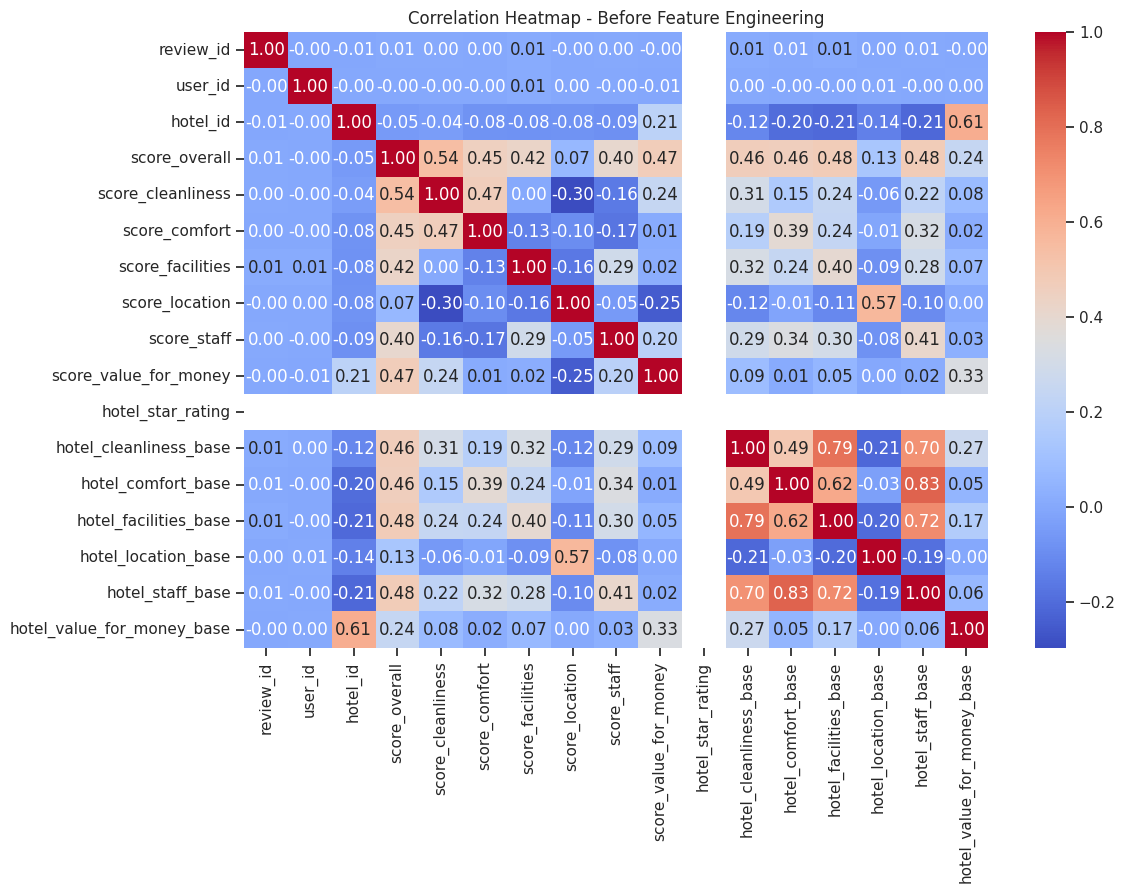

In [22]:
import seaborn as sns
import matplotlib.pyplot as plt

# Select only numerical columns
num_df = merged_df.select_dtypes(include=['float64', 'int64'])

# Correlation matrix
corr_matrix = num_df.corr()

plt.figure(figsize=(12,8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Heatmap - Before Feature Engineering")
plt.show()


# 1. Review Scores Are Very Similar
   - when 'score_cleanliness' is high, 'score_overall' and 'score_comfort' are also high (correlation 0.70 and 0.61).
   - This means users who rate one thing high usually rate everything high.
   - So, these features say almost the same thing. We don’t need all of them.


# 2. Hotel Base Features Are Also Similar
   - 'hotel_staff_base' has a strong link with 'hotel_comfort_base' (0.83) and 'hotel_facilities_base' (0.72).
   - This means good hotels usually have good staff, comfort, and facilities together.
   - These features are very related, so we should combine or  adjust them to avoid repeating the same information.


# 3. What to do
   - Because of these strong connections, we’ll make new features like “difference from hotel average” to remove repeating information and help the model learn better.
   - Keeping both can confuse your model (this is called multicollinearity).

In [23]:
#drop correlated columns
merged_df["hotel_score"] = merged_df[
    ["hotel_staff_base", "hotel_comfort_base", "hotel_facilities_base",
     "hotel_cleanliness_base", "hotel_value_for_money_base",'hotel_location_base']
].mean(axis=1)

# encoding

In [24]:
pip install category-encoders

Note: you may need to restart the kernel to use updated packages.


In [25]:
# merged_df.drop(
#     columns=[
#         "hotel_staff_base", 
#         "hotel_comfort_base", 
#         "hotel_facilities_base",
#         "hotel_cleanliness_base", 
#         "hotel_value_for_money_base",
#         "score_cleanliness",
#         "score_comfort",
#         "score_facilities",
#         "score_location",
#         "score_staff",
#         "score_value_for_money",
#         'review_id',
#         'user_id',
#         'hotel_id',
#         'hotel_location_base',
#         'user_country',
#         'hotel_name' ,
#         'hotel_star_rating',
#         'hotel_country'
#     ],
#     inplace=True
# )

In [26]:
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.utils import to_categorical
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Define columns to keep before splitting
features_to_use = [ 'user_gender', 'user_age_group', 'user_traveller_type']

# Keep the columns needed for aggregation
aggregation_cols = ['hotel_staff_base', 'hotel_comfort_base', 'hotel_facilities_base',
                    'hotel_cleanliness_base', 'hotel_value_for_money_base',
                    'score_cleanliness', 'score_comfort', 'score_facilities',
                    'score_location', 'score_staff', 'score_value_for_money' 
                   ]

# Prepare X and y WITHOUT dropping columns yet
X = merged_df[aggregation_cols ].copy()
y = merged_df['country_group'].copy()

print("Dataset shape:", X.shape)
print("\nTarget distribution:")
print(y.value_counts())
print(f"\nNumber of classes: {y.nunique()}")

2025-10-22 23:44:08.505068: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1761176648.778319      83 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1761176648.859235      83 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


Dataset shape: (50000, 11)

Target distribution:
country_group
Western_Europe          11876
Africa                   6132
East_Asia                6082
Southeast_Asia           4070
Oceania                  4014
Middle_East              3983
North_America            3962
South_America            3918
North_America_Mexico     2004
South_Asia               1989
Eastern_Europe           1970
Name: count, dtype: int64

Number of classes: 11


In [27]:
# ============================================================
# 2. TRAIN-TEST SPLIT FIRST (CRITICAL FOR AVOIDING LEAKAGE)
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"\nTrain size: {X_train.shape}")
print(f"Test size: {X_test.shape}")


Train size: (40000, 11)
Test size: (10000, 11)


In [28]:
print("CALCULATING AGGREGATED FEATURES (NO LEAKAGE)")

# Calculate hotel_score as average of hotel_* columns
hotel_score_cols = ['hotel_staff_base', 'hotel_comfort_base', 'hotel_facilities_base',
                    'hotel_cleanliness_base', 'hotel_value_for_money_base']

X_train['hotel_score'] = X_train[hotel_score_cols].mean(axis=1)
X_test['hotel_score'] = X_test[hotel_score_cols].mean(axis=1)

#Calculate score_overall_agg as average of score_* columns
score_cols = ['score_cleanliness', 'score_comfort', 'score_facilities',
             'score_location', 'score_staff', 'score_value_for_money']

X_train['score_overall_agg'] = X_train[score_cols].mean(axis=1)
X_test['score_overall_agg'] = X_test[score_cols].mean(axis=1)

print("Aggregated features calculated separately for train and test")

CALCULATING AGGREGATED FEATURES (NO LEAKAGE)
Aggregated features calculated separately for train and test


In [ ]:
columns_to_drop = hotel_score_cols #+ score_cols

X_train.drop(columns=columns_to_drop, inplace=True)
X_test.drop(columns=columns_to_drop, inplace=True)

print(f"✓ Dropped aggregation columns")
print(f"Final features: {list(X_train.columns)}")

In [ ]:
# ============================================================
# 5. ENCODE CATEGORICAL FEATURES (FIT ON TRAIN ONLY)
# ============================================================

print("\n" + "="*60)
print("ENCODING FEATURES")
print("="*60)

# One-Hot Encoding: user_gender
#X_train = pd.get_dummies(X_train, columns=['user_gender'], prefix='gender', drop_first=True)
#X_test = pd.get_dummies(X_test, columns=['user_gender'], prefix='gender', drop_first=True)

# Ordinal Encoding: user_age_group
#age_mapping = {'18-24': 0, '25-34': 1, '35-44': 2, '45-54': 3, '55+': 4}
#X_train['user_age_group'] = X_train['user_age_group'].map(age_mapping)
#X_test['user_age_group'] = X_test['user_age_group'].map(age_mapping)

# One-Hot Encoding: user_traveller_type
#X_train = pd.get_dummies(X_train, columns=['user_traveller_type'], drop_first=True)
#X_test = pd.get_dummies(X_test, columns=['user_traveller_type'], drop_first=True)

# Align columns (ensure test has same columns as train)
X_train, X_test = X_train.align(X_test, join='left', axis=1, fill_value=0)

print(f"✓ Features after encoding: {X_train.shape[1]}")

In [ ]:
X_train.columns

In [ ]:
# ============================================================
# 6. SCALE FEATURES (FIT ON TRAIN ONLY, TRANSFORM BOTH)
# ============================================================

print("\nScaling features...")
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)  # Fit on train only
X_test_scaled = scaler.transform(X_test)        # Transform test using train stats

print(f"✓ Features after scaling: {X_train_scaled.shape[1]}")

In [ ]:
# ============================================================
# 7. ENCODE TARGET VARIABLE (FIT ON TRAIN ONLY)
# ============================================================


print("\nEncoding target variable...")
le_target = LabelEncoder()
y_train_encoded = le_target.fit_transform(y_train)  # Fit on train only
y_test_encoded = le_target.transform(y_test)

# Convert to categorical (one-hot encoding for neural network)
n_classes = len(le_target.classes_)
y_train_categorical = to_categorical(y_train_encoded, num_classes=n_classes)
y_test_categorical = to_categorical(y_test_encoded, num_classes=n_classes)

print(f"Number of classes: {n_classes}")
print(f"Classes: {le_target.classes_}")
print(f"Target shape: {y_train_categorical.shape}")

print("\n" + "="*60)
print("DATA PREPARATION COMPLETE - NO DATA LEAKAGE")
print("="*60)
print("\n✓ Train-test split performed BEFORE aggregation")
print("✓ Aggregates calculated independently on train and test")
print("✓ Scaling fitted on training data only")
print("✓ Encoding fitted on training data only")

In [ ]:
# BUILD NEURAL NETWORK MODEL

# Get input dimension
input_dim = X_train_scaled.shape[1]

# Build model
model = models.Sequential([
    layers.Dense(128, activation='relu', input_dim=input_dim, name='hidden_layer_1'),
    layers.Dropout(0.3),
    layers.Dense(64, activation='relu', name='hidden_layer_2'),
    layers.Dropout(0.3),
    layers.Dense(32, activation='relu', name='hidden_layer_3'),
    layers.Dense(n_classes, activation='softmax', name='output_layer')
])

# Compile model
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [ ]:
#TRAIN THE MODEL

# Define callbacks
early_stopping = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True,
    verbose=1
)

# Train model
history = model.fit(
    X_train_scaled, y_train_categorical,
    validation_split=0.2,
    epochs=100,
    batch_size=32,
    callbacks=early_stopping,
    verbose=1
)

In [ ]:
#EVALUATE THE MODEL

# Evaluate on test set
test_loss, test_accuracy = model.evaluate(X_test_scaled, y_test_categorical, verbose=0)
print(f"\nTest Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

# Make predictions
y_pred_proba = model.predict(X_test_scaled)
y_pred = np.argmax(y_pred_proba, axis=1)

# Classification report
print("CLASSIFICATION REPORT")
print(classification_report(y_test_encoded, y_pred, target_names=le_target.classes_))


In [ ]:
# VISUALIZATIONS

# Plot training history
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Loss plot
axes[0].plot(history.history['loss'], label='Training Loss', linewidth=2)
axes[0].plot(history.history['val_loss'], label='Validation Loss', linewidth=2)
axes[0].set_title('Model Loss', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Accuracy plot
axes[1].plot(history.history['accuracy'], label='Training Accuracy', linewidth=2)
axes[1].plot(history.history['val_accuracy'], label='Validation Accuracy', linewidth=2)
axes[1].set_title('Model Accuracy', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
#plt.savefig('training_history.png', dpi=300, bbox_inches='tight')
plt.show()

# Confusion Matrix
plt.figure(figsize=(12, 10))
cm = confusion_matrix(y_test_encoded, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=le_target.classes_, 
            yticklabels=le_target.classes_,
            cbar_kws={'label': 'Count'})
plt.title('Confusion Matrix - Neural Network', fontsize=16, fontweight='bold')
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
#plt.savefig('confusion_matrix.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
#RANDOM FOREST
from sklearn.ensemble import RandomForestClassifier
print("TRAINING RANDOM FOREST MODEL (as verification)")

rft = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1)
rft.fit(X_train, y_train_encoded)

y_pred = rft.predict(X_test)

print("\nTEST ACCURACY:", accuracy_score(y_test_encoded, y_pred))
print("\nCLASSIFICATION REPORT:")
print(classification_report(y_test_encoded, y_pred, target_names=le_target.classes_))

In [ ]:
import shap
import numpy as np
import pandas as pd

# Use a small subset for speed
X_shap = X_train.sample(1000, random_state=42)

# Function that returns model prediction with correct feature names
def f(X):
    return rft.predict(pd.DataFrame(X, columns=X_train.columns))

# KernelExplainer for any model
explainer = shap.KernelExplainer(f, X_shap)

# Calculate SHAP values (first 20 test samples)
shap_values = explainer.shap_values(X_test.iloc[:20])

# Summary plot
shap.summary_plot(shap_values, X_test.iloc[:20])


In [ ]:
index = 5
sample = X_test.iloc[index:index+1]

# Get predicted class for this specific sample
pred_class_index = rft.predict(sample)[0]
pred_class_name = le_target.inverse_transform([pred_class_index])[0]

print(f"Prediction for sample {index}: {pred_class_name}")

# SHAP force plot
shap.initjs()
shap.force_plot(
    explainer.expected_value,
    shap_values[index],
    sample
)


In [ ]:
index = 0
sample = X_test.iloc[index:index+1]

# Get predicted class for this specific sample
pred_class_index = rft.predict(sample)[0]
pred_class_name = le_target.inverse_transform([pred_class_index])[0]

print(f"Prediction for sample {index}: {pred_class_name}")

# SHAP force plot
shap.initjs()
shap.force_plot(
    explainer.expected_value,
    shap_values[index],
    sample
)
